# 👄 Mouth State CNN — v2 (Synapse)

**الهدف:** نموذج CNN مبني من الصفر بيصنّف صورة الفم: **طبيعي (0)** أو **تثاؤب (1)**.

| | |
|---|---|
| **الداتا** | صور الفم يلي طلّعناها من NITYMED بسكربت منار (`build_mouth_dataset.py`) — output نوتبوك `deep learning1` |
| **المدخل** | صورة ملونة RGB بحجم 96×96×3، قيمها بين 0 و 1 |
| **المخرج** | احتمال إنه الشخص **بيتثاءب** (sigmoid) |
| **الملفات الناتجة** | الأوزان، منحنيات التدريب، Confusion Matrix، تقرير الدقة |

> **ليش v2؟** النسخة الأولى (baseline) تعلّمت الـ train (accuracy 98%) بس على فيديوهات جديدة جاوبت "no_yawn" لكل الصور
> (val accuracy ثابتة 45%، test 49.8%). النوتبوك هاد: **(أ) بيشخّص السبب بالأرقام**، **(ب) بيدرّب نسخة مصلّحة**.

## 1) تجهيز البيئة
- **ليش clone للريبو؟** عشان نستخدم `make_mouth_dataset` تبع منار ← نفس المعالجة بالتدريب والـ real-time (`preprocess_mouth`).
- **`set_random_seed(42)`** ← نتائج قابلة للتكرار.

In [1]:
import os, sys, json, glob
if not os.path.exists("Synapse"):
    !git clone -q https://github.com/ManarAbu-Irsheid/Synapse.git
sys.path.insert(0, "Synapse/data_pipeline")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from mouth_dataset import make_mouth_dataset      # loader تبع Member 1

tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2) الإعدادات (Hyperparameters)
- `IMG_SIZE = 96` لأنه هيك بيقص سكربت منار الفم، وهيك بيعالج `preprocess_mouth` بالـ real-time.
- باقي الإعدادات نفس مودل العين ← المقارنة بين المودلين عادلة.

In [2]:
OUT         = "/kaggle/working/mouth_cnn_v2"
SPLITS_OUT  = "/kaggle/working/mouth_splits"
IMG_SIZE    = 96
BATCH       = 64
EPOCHS      = 30
LR          = 1e-3
CLASS_NAMES = ["no_yawn", "yawn"]        # 0 = طبيعي، 1 = تثاؤب
os.makedirs(OUT, exist_ok=True); os.makedirs(SPLITS_OUT, exist_ok=True)

## 3) إيجاد الداتا وتصليح المسارات
- **المشكلة:** ملفات الـ CSV انكتبت وقت ما كانت الصور بـ `/kaggle/working/nitymed_out/...`. لما نضيف نوتبوك `deep learning1` كـ Input، نفس الصور بتصير تحت `/kaggle/input/...`.
- **الحل:** بندوّر على مجلد `nitymed_out` لحاله، وبنبدّل أول المسار بالمكان الجديد.
- **وبنخلط ملف الـ train كامل** (نفس درس مودل العين: الصور مرتبة حسب الفيديو والفريم، فالـ batches بتطلع غير مخلوطة).

In [3]:
found = glob.glob("/kaggle/input/**/nitymed_out/labels/mouth_train.csv", recursive=True)
assert found, "ما لقيت داتا الفم! ضيفي output نوتبوك deep learning1 كـ Input (Add Input ← Your Work)."
ROOT = os.path.dirname(os.path.dirname(found[0]))          # .../nitymed_out
print("📂 الداتا موجودة بـ:", ROOT)

OLD_ROOT = "/kaggle/working/nitymed_out"
dfs = {}
for s in ["train", "val", "test"]:
    d = pd.read_csv(f"{ROOT}/labels/mouth_{s}.csv")
    d["path"] = d["path"].str.replace(OLD_ROOT, ROOT, regex=False)
    if s == "train":
        d = d.sample(frac=1, random_state=42).reset_index(drop=True)   # خلط كامل
    d.to_csv(f"{SPLITS_OUT}/mouth_{s}.csv", index=False)
    dfs[s] = d

for s, d in dfs.items():
    c = d.label.value_counts().sort_index()
    print(f"{s:5s}: {len(d):5d} images | videos={d.video.nunique():3d} | no_yawn={c.get(0,0)} yawn={c.get(1,0)} ({c.get(1,0)/len(d):.0%})")

missing = [p for p in dfs["train"].path.head(20) if not os.path.exists(p)]
assert not missing, f"مسارات الصور غلط! مثال: {missing[0]}"
lab = dfs["train"].label.values
n = min(10, len(lab) // BATCH)
print(f"نسبة yawn بأول {n} batches بعد الخلط:", lab[:n * BATCH].reshape(n, BATCH).mean(1).round(2))
print("✅ المسارات سليمة")

📂 الداتا موجودة بـ: /kaggle/input/notebooks/halasaadabushendi/deep-learning1/nitymed_out
train:  5398 images | videos= 60 | no_yawn=2700 yawn=2698 (50%)
val  :  1010 images | videos= 13 | no_yawn=455 yawn=555 (55%)
test :  1276 images | videos= 14 | no_yawn=636 yawn=640 (50%)
نسبة yawn بأول 10 batches بعد الخلط: [0.47 0.5  0.45 0.47 0.39 0.52 0.52 0.59 0.44 0.48]
✅ المسارات سليمة


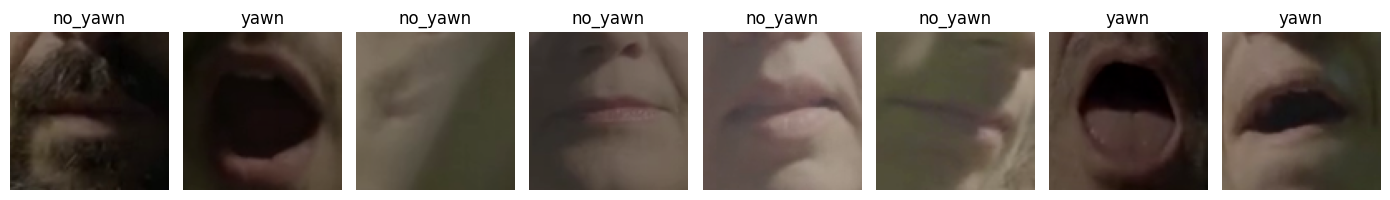

batch shape: (64, 96, 96, 3) | min/max: 0.0 0.7246233224868774


In [4]:
train_ds = make_mouth_dataset(f"{SPLITS_OUT}/mouth_train.csv", training=True,  batch_size=BATCH, size=IMG_SIZE)
val_ds   = make_mouth_dataset(f"{SPLITS_OUT}/mouth_val.csv",   training=False, batch_size=BATCH, size=IMG_SIZE)
test_ds  = make_mouth_dataset(f"{SPLITS_OUT}/mouth_test.csv",  training=False, batch_size=BATCH, size=IMG_SIZE)

imgs, labels = next(iter(train_ds))
plt.figure(figsize=(14, 3.2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(imgs[i].numpy()); plt.title(CLASS_NAMES[int(labels[i])]); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/samples.png", dpi=120); plt.show()
print("batch shape:", imgs.shape, "| min/max:", float(tf.reduce_min(imgs)), float(tf.reduce_max(imgs)))

## 4) تشخيص مشكلة النسخة الأولى
**الأعراض:** train accuracy 98% بس val accuracy ثابتة 45% من أول epoch، وكل التوقعات "no_yawn".

**الفرضية:** في **إزاحة (shift)** بين صور فيديوهات الـ train وصور فيديوهات الـ val/test (إضاءة، سائقين، كاميرا).
طبقات **BatchNorm** وقت التقييم بتستخدم "متوسط وتباين" محفوظين من الـ train، فلما تيجي صور شكلها مختلف،
كل المخرجات بتنزاح لنفس الجهة.

**الفحوصات:**
1. **إحصائيات البكسلات** (متوسط/انحراف الإضاءة) لكل قسم ← لو مختلفة كثير، في إزاحة.
2. **AUC الحقيقي (sklearn)** لمودل v1 ← لو عالي، يعني المودل **بيرتّب** الصور صح بس كل التوقعات منزاحة (مشكلة معايرة/BatchNorm).
3. **إعادة حساب إحصائيات BatchNorm** على صور الـ val (تجربة تشخيصية بس) ← لو صلّحت النتيجة، تأكدنا إنه السبب هو الإزاحة + BatchNorm.

,split,mean_brightness,std,mean_RGB
0,train,0.286488,0.111970,"[0.329, 0.284, 0.249]"
1,val,0.303648,0.116679,"[0.348, 0.3, 0.265]"
2,test,0.295331,0.116937,"[0.338, 0.292, 0.258]"


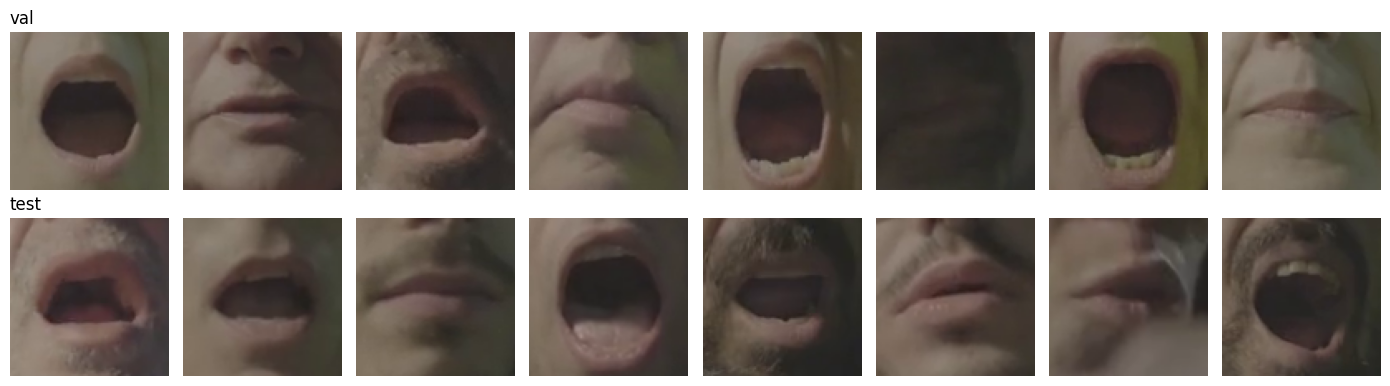

In [5]:
def pixel_stats(d, n=300):
    paths = d.path.sample(min(n, len(d)), random_state=0)
    px = np.stack([plt.imread(p)[..., :3] for p in paths]).astype("float32")
    if px.max() > 1.5: px /= 255.0
    return px.mean(), px.std(), px.mean(axis=(0, 1, 2)).round(3)

stats = pd.DataFrame([dict(zip(["split", "mean_brightness", "std", "mean_RGB"], (s, *pixel_stats(d))))
                      for s, d in dfs.items()])
display(stats)

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for r, s in enumerate(["val", "test"]):
    for i, p in enumerate(dfs[s].sample(8, random_state=1).path):
        ax[r, i].imshow(plt.imread(p)); ax[r, i].axis("off")
    ax[r, 0].set_title(s, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT}/val_test_samples.png", dpi=100); plt.show()

In [6]:
v1_found = glob.glob("/kaggle/input/**/mouth_cnn_baseline/mouth_cnn_baseline.keras", recursive=True)
if not v1_found:
    print("ℹ️ ما لقيت مودل v1 — ضيفي output نوتبوك mouth-CNN-training كـ Input لو بدك التشخيص. (التدريب تحت بيكمّل عادي)")
else:
    y_val = dfs["val"].label.values
    def check(m, name):
        p = m.predict(val_ds, verbose=0).ravel()
        return {"v1 model": name, "val_AUC (sklearn)": roc_auc_score(y_val, p),
                "val_accuracy@0.5": ((p >= 0.5) == y_val).mean(), "mean p_yawn": p.mean()}

    def recalibrate_bn(m, ds, passes=3):
        for l in m.layers:
            if isinstance(l, layers.BatchNormalization):
                l.momentum = 0.9
        for _ in range(passes):
            for x, _ in ds:
                m(x, training=True)          # بيحدّث إحصائيات BatchNorm بس (ما في تدريب للأوزان)

    rows = []
    v1 = keras.models.load_model(v1_found[0]); rows.append(check(v1, "as trained"))
    v1 = keras.models.load_model(v1_found[0])
    recalibrate_bn(v1, make_mouth_dataset(f"{SPLITS_OUT}/mouth_train.csv", training=False, batch_size=BATCH, size=IMG_SIZE))
    rows.append(check(v1, "BN stats re-estimated on train"))
    v1 = keras.models.load_model(v1_found[0]); recalibrate_bn(v1, val_ds)
    rows.append(check(v1, "BN stats re-estimated on val (diagnostic only)"))
    diag = pd.DataFrame(rows).set_index("v1 model")
    diag.to_csv(f"{OUT}/diagnosis_v1.csv")
    display(diag.style.format("{:.4f}"))

ℹ️ ما لقيت مودل v1 — ضيفي output نوتبوك mouth-CNN-training كـ Input لو بدك التشخيص. (التدريب تحت بيكمّل عادي)


## 5) بناء النموذج v2 — التصليحات
نفس المعمارية (3 بلوكات Conv: 32 ← 64 ← 128)، مع **3 تصليحات** موجهة للمشكلة:

| التصليح | الطبقة | ليش؟ |
|---|---|---|
| **1) توحيد كل صورة لحالها** | `LayerNormalization` على الصورة كاملة (per-image standardization) | كل صورة بتنطرح منها إضاءتها وبتنقسم على تباينها ← فرق الإضاءة بين الفيديوهات بيختفي قبل ما يوصل للـ Conv |
| **2) augmentation أقوى للإضاءة** | `RandomBrightness(0.3)` + `RandomContrast(0.4)` + قلب أفقي | المودل بيشوف إضاءات متنوعة وقت التدريب ← ما بيتعلق بإضاءة فيديوهات الـ train |
| **3) BatchNorm أسرع بالتحديث** | `momentum = 0.9` بدل 0.99 | عنا 85 خطوة بس بكل epoch (داتا صغيرة)، فالإحصائيات المحفوظة لازم تلحق التدريب أسرع |

> الطبقات الثلاث **جوّا النموذج** ← المدخل بيضل نفسه (96×96×3 بين 0 و 1 من `preprocess_mouth`)، والـ augmentation بيشتغل وقت التدريب بس.

In [7]:
def conv_block(x, filters, drop):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization(momentum=0.9)(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(drop)(x)

def build_mouth_cnn(img_size=IMG_SIZE):
    inp = keras.Input((img_size, img_size, 3), name="mouth_rgb")
    x = layers.RandomFlip("horizontal")(inp)                          # augmentation (training بس)
    x = layers.RandomBrightness(0.3, value_range=(0.0, 1.0))(x)
    x = layers.RandomContrast(0.4)(x)
    x = layers.LayerNormalization(axis=[1, 2, 3], center=False, scale=False,
                                  epsilon=1e-3, name="per_image_standardization")(x)
    x = conv_block(x, 32, 0.20)       # 96 -> 48
    x = conv_block(x,   64, 0.25)     # 48 -> 24
    x = conv_block(x,  128, 0.30)     # 24 -> 12
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(1, activation="sigmoid", name="p_yawn")(x)
    return keras.Model(inp, out, name="mouth_cnn_v2")

model = build_mouth_cnn()
model.summary()

Model: "mouth_cnn_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mouth_rgb (InputLayer)          │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 96, 96, 3)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 96, 96, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ per_image_standardization       │ (None, 96, 96, 3)      │             0 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 304,993 (1.16 MB)

 Trainable params: 304,097 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

## 6) التدريب
نفس إعدادات العين: **Adam** + **binary_crossentropy** + نفس الـ callbacks
(EarlyStopping، ReduceLROnPlateau، ModelCheckpoint، CSVLogger).

In [8]:
model.compile(
    optimizer=keras.optimizers.Adam(LR),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")],
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(f"{OUT}/best.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.CSVLogger(f"{OUT}/history.csv"),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/30


E0000 00:00:1795289912.323578      77 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


84/85 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.7809 - auc: 0.8577 - loss: 0.4797 - precision: 0.7827 - recall: 0.7697

E0000 00:00:1795290011.518201      79 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


85/85 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.8824 - auc: 0.9574 - loss: 0.3148 - precision: 0.8894 - recall: 0.8732 - val_accuracy: 0.9515 - val_auc: 0.9964 - val_loss: 0.1763 - val_precision: 0.9828 - val_recall: 0.9279 - learning_rate: 0.0010
Epoch 2/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.9629 - auc: 0.9926 - loss: 0.1483 - precision: 0.9674 - recall: 0.9581 - val_accuracy: 0.9614 - val_auc: 0.9950 - val_loss: 0.1361 - val_precision: 0.9691 - val_recall: 0.9604 - learning_rate: 0.0010
Epoch 3/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.9678 - auc: 0.9925 - loss: 0.1436 - precision: 0.9727 - recall: 0.9626 - val_accuracy: 0.9683 - val_auc: 0.9939 - val_loss: 0.1364 - val_precision: 0.9564 - val_recall: 0.9874 - learning_rate: 0.0010
Epoch 4/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.9744 - auc: 0.9962 - loss: 0.1186 - precision: 0.9783 - recall: 0.9703 - val_accuracy: 0.9644 - val_auc: 0.9966 - val_loss: 0.1328 - val_precision: 0.9

## 7) منحنيات التدريب
- train و val ماشيين مع بعض ← ممتاز.
- train بيتحسن و val بيسوء ← Overfitting (متوقع أكثر هون لأنه الداتا صغيرة).

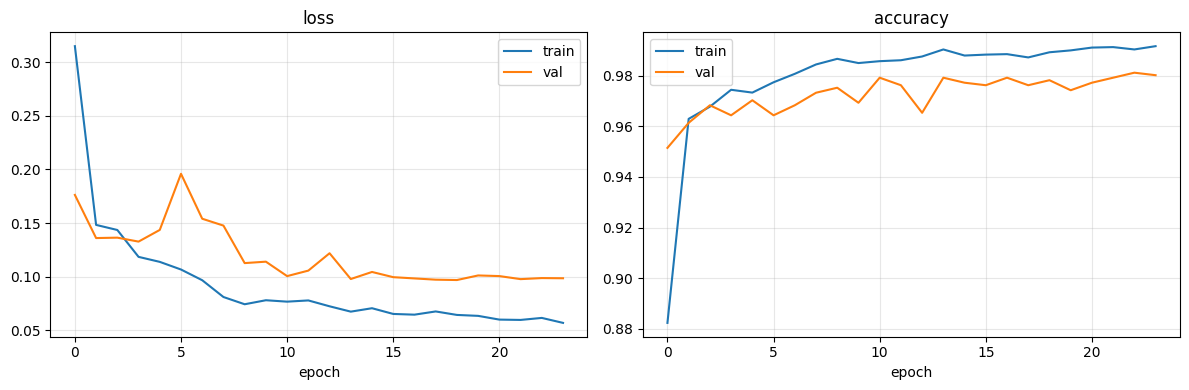

In [9]:
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(h[m], label="train"); ax[i].plot(h[f"val_{m}"], label="val")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend(); ax[i].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.show()

## 8) التقييم على الـ Test Set
- الـ test = 14 فيديو المودل ما شافهم أبداً.
- **أهم رقم: Recall لفئة yawn** — من كل التثاؤبات الحقيقية، كم وحدة اكتشف المودل؟

Test AUC (sklearn): 0.9993

              precision    recall  f1-score   support

     no_yawn     0.9874    0.9843    0.9858       636
        yawn     0.9844    0.9875    0.9860       640

    accuracy                         0.9859      1276
   macro avg     0.9859    0.9859    0.9859      1276
weighted avg     0.9859    0.9859    0.9859      1276



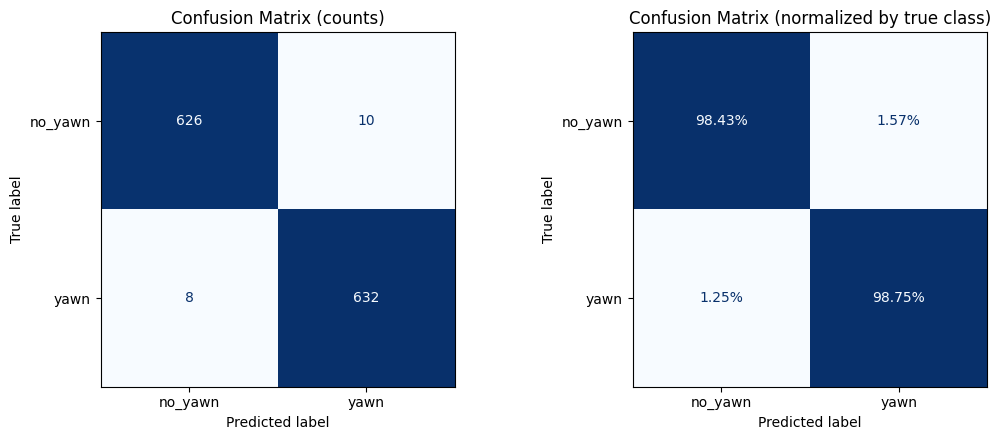

In [10]:
y_true = dfs["test"].label.values
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
print(f"Test AUC (sklearn): {roc_auc_score(y_true, y_prob):.4f}"); print()

report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"),
                       display_labels=CLASS_NAMES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2%")
ax[1].set_title("Confusion Matrix (normalized by true class)")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=120); plt.show()

## 9) حفظ النموذج والنتائج

In [11]:
model.save(f"{OUT}/mouth_cnn_v2.keras")
model.save_weights(f"{OUT}/mouth_cnn_v2.weights.h5")

test_eval = model.evaluate(test_ds, verbose=0, return_dict=True)
metrics = {
    "model": "mouth_cnn_v2",
    "params": int(model.count_params()),
    "epochs_trained": len(h),
    "best_val_loss": float(h.val_loss.min()),
    "test_accuracy": report["accuracy"],
    "test_auc": float(roc_auc_score(y_true, y_prob)),
    "no_yawn": {k: report["no_yawn"][k] for k in ["precision", "recall", "f1-score", "support"]},
    "yawn":    {k: report["yawn"][k]    for k in ["precision", "recall", "f1-score", "support"]},
    "confusion_matrix": cm.tolist(),
    "hyperparameters": {"img_size": IMG_SIZE, "batch": BATCH, "lr": LR, "max_epochs": EPOCHS,
                        "fixes": ["per-image standardization", "brightness/contrast augmentation", "BN momentum 0.9"]},
}
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("\nFiles:", sorted(os.listdir(OUT)))

{
  "model": "mouth_cnn_v2",
  "params": 304993,
  "epochs_trained": 24,
  "best_val_loss": 0.09697172790765762,
  "test_accuracy": 0.9858934169278997,
  "test_auc": 0.9992850825471697,
  "no_yawn": {
    "precision": 0.9873817034700315,
    "recall": 0.9842767295597484,
    "f1-score": 0.9858267716535433,
    "support": 636.0
  },
  "yawn": {
    "precision": 0.9844236760124611,
    "recall": 0.9875,
    "f1-score": 0.9859594383775351,
    "support": 640.0
  },
  "confusion_matrix": [
    [
      626,
      10
    ],
    [
      8,
      632
    ]
  ],
  "hyperparameters": {
    "img_size": 96,
    "batch": 64,
    "lr": 0.001,
    "max_epochs": 30,
    "fixes": [
      "per-image standardization",
      "brightness/contrast augmentation",
      "BN momentum 0.9"
    ]
  }
}

Files: ['best.keras', 'confusion_matrix.png', 'history.csv', 'metrics.json', 'mouth_cnn_v2.keras', 'mouth_cnn_v2.weights.h5', 'samples.png', 'training_curves.png', 'val_test_samples.png']


## 10) استخدام النموذج بالـ real-time (للفريق)
```python
from tensorflow import keras
from face_utils import preprocess_mouth
model = keras.models.load_model("mouth_cnn_v2.keras")
x = preprocess_mouth(mouth_roi_bgr)            # (96, 96, 3) RGB
p_yawn = model.predict(x[None], verbose=0)[0, 0]
yawning = p_yawn >= 0.5
```

**حدود الداتا (للتقرير):**
- الـ labels أوتوماتيكية (قاعدة MAR > 0.25 لمدة ≥ 1.5 ثانية)، مش يدوية.
- التقسيم حسب الفيديو مش حسب السائق (حوالي 21 سائق) ← نتيجة الـ test ممكن تكون متفائلة شوي.
- الكلام والغناء ما انفحصوا ← المودل ممكن يخلط بين فم مفتوح وتثاؤب.